Accuracy: 0.8833333333333333

Classification Report:
                                                          precision    recall  f1-score   support

                                        Abdominal Hernia       1.00      1.00      1.00         1
                                        Abdominal Injury       0.67      1.00      0.80         2
                                                 Abscess       1.00      1.00      1.00         3
                                     Abscess of the Lung       1.00      1.00      1.00         1
                                               Achalasia       0.33      1.00      0.50         1
                                   Acinic cell carcinoma       1.00      1.00      1.00         1
                                       Actinic Keratosis       1.00      1.00      1.00         1
                                          Acute Glaucoma       1.00      1.00      1.00         2
                                     Acute Kidney Injury       1

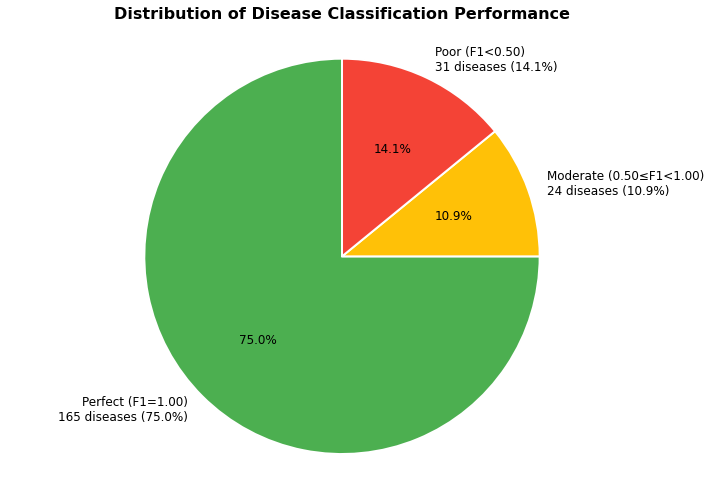


CSV file generated successfully at C:\Users\Vishnu\Downloads\data\disease_diagnosis_treatment.csv.

Enter your symptoms (comma-separated): Fever , bodypains

Here are some potential diseases you might have:
- Chagas Disease
- Empyema
- West Nile Virus
- Pyelonephritis

Testing prediction with a sample symptoms file

Disease prediction and their treatments:
+------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
| Disease             

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report
from tabulate import tabulate
import warnings
import matplotlib.pyplot as plt

# Suppress specific warnings
warnings.filterwarnings("ignore", category=UserWarning, message=".*The least populated class.*")
warnings.filterwarnings("ignore", message="Number of classes in training fold.*")

# Load data
data = pd.read_csv(r"C:\Users\Vishnu\Downloads\data\disease_train.csv.xls")
treatment = pd.read_csv(r"C:\Users\Vishnu\Downloads\data\treatment_dataset.csv.xls")
test_data = pd.read_csv(r"C:\Users\Vishnu\Downloads\data\disease_test.csv.xls")

# Data Preprocessing
tfidf_vectorizer = TfidfVectorizer(max_features=500)
X_train = tfidf_vectorizer.fit_transform(data['symptoms'])
y_train = data['disease']
X_test = tfidf_vectorizer.transform(test_data['symptoms'])
y_test = test_data['disease']

# Create a list of unique symptoms
data['symptoms_list'] = data['symptoms'].apply(lambda x: x.split(','))
data['symptoms_list'] = data['symptoms_list'].apply(lambda x: [i.lower() for i in x])
all_symptoms = [symptom for symptoms_list in data['symptoms_list'] for symptom in symptoms_list]
unique_symptoms = set(all_symptoms)

# Model Implementation
estimators = [
    ('rf', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)),
    ('xgb', XGBClassifier(eval_metric='mlogloss', random_state=42, n_jobs=-1))
]
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
stacking_clf = StackingClassifier(
    estimators=estimators, 
    cv=cv, 
    final_estimator=LogisticRegression(solver='saga', max_iter=100, random_state=42)
)
stacking_clf.fit(X_train, y_train)

def process_classification_results(report_dict):
    """
    Process classification report into performance tiers.
    Returns counts of diseases in each performance category.
    """
    # Filter out summary metrics
    disease_scores = {k: v for k, v in report_dict.items() 
                     if k not in ['accuracy', 'macro avg', 'weighted avg']}
    
    # Count diseases in each category
    perfect_count = sum(1 for _, metrics in disease_scores.items() if metrics['f1-score'] == 1.0)
    moderate_count = sum(1 for _, metrics in disease_scores.items() if 0.5 <= metrics['f1-score'] < 1.0)
    poor_count = sum(1 for _, metrics in disease_scores.items() if metrics['f1-score'] < 0.5)
    
    return perfect_count, moderate_count, poor_count

def create_performance_visualization(report_dict):
    """
    Create and display an enhanced pie chart showing the distribution of model performance.
    """
    # Get performance counts
    perfect_count, moderate_count, poor_count = process_classification_results(report_dict)
    total = perfect_count + moderate_count + poor_count
    
    # Calculate percentages
    percentages = [
        (perfect_count / total) * 100,
        (moderate_count / total) * 100,
        (poor_count / total) * 100
    ]
    
    # Create figure with larger size
    plt.figure(figsize=(12, 8))
    
    # Define colors and labels
    colors = ['#4CAF50', '#FFC107', '#F44336']
    labels = [
        f'Perfect (F1=1.00)\n{perfect_count} diseases ({percentages[0]:.1f}%)',
        f'Moderate (0.50≤F1<1.00)\n{moderate_count} diseases ({percentages[1]:.1f}%)',
        f'Poor (F1<0.50)\n{poor_count} diseases ({percentages[2]:.1f}%)'
    ]
    
    # Create pie chart with enhanced styling
    plt.pie(percentages, 
           labels=labels,
           colors=colors,
           autopct='%1.1f%%',
           startangle=90,
           wedgeprops={'edgecolor': 'white', 'linewidth': 2},
           textprops={'fontsize': 12})
    
    # Add title with larger font
    plt.title('Distribution of Disease Classification Performance', 
             pad=20, 
             fontsize=16, 
             fontweight='bold')
    
    # Ensure the pie chart is circular
    plt.axis('equal')
    
    # Save the visualization with high resolution
    plt.savefig('disease_classification_performance.png', 
                bbox_inches='tight', 
                dpi=300,
                facecolor='white',
                edgecolor='none')
    
    print("\nVisualization saved as 'disease_classification_performance.png'")
    
    # Display the plot
    plt.show()

# Predictions and evaluation
stacking_preds = stacking_clf.predict(X_test)
print("Accuracy:", accuracy_score(y_test, stacking_preds))

# Get detailed classification report
report_dict = classification_report(y_test, stacking_preds, zero_division=1, output_dict=True)

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, stacking_preds, zero_division=1))

# Create visualization
create_performance_visualization(report_dict)

# Function to map diseases to treatments
def disease_treatment(y_preds):
    treatment_list = {}
    for disease in y_preds:
        if disease in treatment['disease'].values:
            treatment_list[disease] = treatment.loc[treatment['disease'] == disease, 'treatment'].values[0]
        else:
            treatment_list[disease] = "Treatment not available"
    return treatment_list

# Save predictions and treatments to a CSV file
output_path = r"C:\Users\Vishnu\Downloads\data\disease_diagnosis_treatment.csv"
treatment_dict = disease_treatment(stacking_preds)
df = pd.DataFrame(list(treatment_dict.items()), columns=['Disease', 'Treatment'])
df.to_csv(output_path, index=False, encoding='utf-8')
print(f"\nCSV file generated successfully at {output_path}.")

# Function for user input diagnosis
def disease_diagnosis_using_user_input(unique_symptoms, data):
    disease_diagnosis_dict = {}
    flag = 0
    unique_symptoms = list(unique_symptoms)
    symptoms = input("\nEnter your symptoms (comma-separated): ")
    symptoms = symptoms.split(",")
    symptoms = [(i.strip()).lower() for i in symptoms]
    for symptom in symptoms:
        if symptom in unique_symptoms:
            flag = 1
            potential_diseases = list(data[data['symptoms_list'].apply(lambda x: symptom in x)]['disease'])
            for disease in potential_diseases:
                if disease in disease_diagnosis_dict:
                    disease_diagnosis_dict[disease] += 1
                else:
                    disease_diagnosis_dict[disease] = 1
    if flag == 0:
        print("Sorry, no matching symptoms found in our database.")
        return
    disease_diagnosis_dict = dict(sorted(disease_diagnosis_dict.items(), key=lambda item: item[1], reverse=True))
    top_diseases = list(disease_diagnosis_dict.keys())[:5]
    print("\nHere are some potential diseases you might have:")
    [print(f"- {disease}") for disease in top_diseases]

# Function to predict disease and treatment from a file
def predict_disease_treatment(file_path, model):
    Xdata = pd.read_csv(file_path)
    X = tfidf_vectorizer.transform(Xdata['symptoms'])
    model_preds = model.predict(X)
    print("\nDisease prediction and their treatments:")
    table_data = [(disease, treatment) for disease, treatment in disease_treatment(model_preds).items()]
    print(tabulate(table_data, headers=["Disease", "Treatment"], tablefmt="grid"))

# Call user input function
disease_diagnosis_using_user_input(unique_symptoms, data)

# Test prediction function with a file
print("\nTesting prediction with a sample symptoms file")
predict_disease_treatment(r"C:\Users\Vishnu\Downloads\data\prediction_test.csv.xls", stacking_clf)